In [75]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

date_columns = ["last_scraped", "calendar_last_scraped", "first_review", "last_review"]

listings = pd.read_csv("data/listings_clean.csv", parse_dates=date_columns)

print(listings.shape)

(4574, 73)


## Part 2: Go deeper

In [76]:
listings["has_reviews"].value_counts()

has_reviews
True     3930
False     644
Name: count, dtype: int64

In [77]:
only_has_reviews = listings[listings["has_reviews"]]

only_has_reviews["has_reviews"].value_counts()

has_reviews
True    3930
Name: count, dtype: int64

### 1.

- The spread of ratings seem to tighten with more reviews, with that effect being more pronounced under 50 reviews
- At very few reviews we have a wide spread with both endpoints represented (1 to 5)
- As we come to 50 reviews the spread has tightened to about 4.2 to 5 with very few outliers after that point
- Over all the spread seems to tighten all the way to the limit at 300 reviews where the spread is between about 4.6 and 5
****
- The limit of 'number_of_reviews' from 0 to 300 excludes 91 values and does not affect the general shape of the plot.
****
- The plot tells us that if the number of reviews that are a few, low value reviews probably has a bigger effect on review_scores_rating. And probably because a really low score can move the average a lot if there are not that many reviews.
- This effect wouldnt be that dramatic if the average review-scores where not so heavily leaning towards the top of the spectrum (5).

In [78]:
excluded = only_has_reviews["number_of_reviews"] > 300

print(only_has_reviews[excluded].shape[0])

91


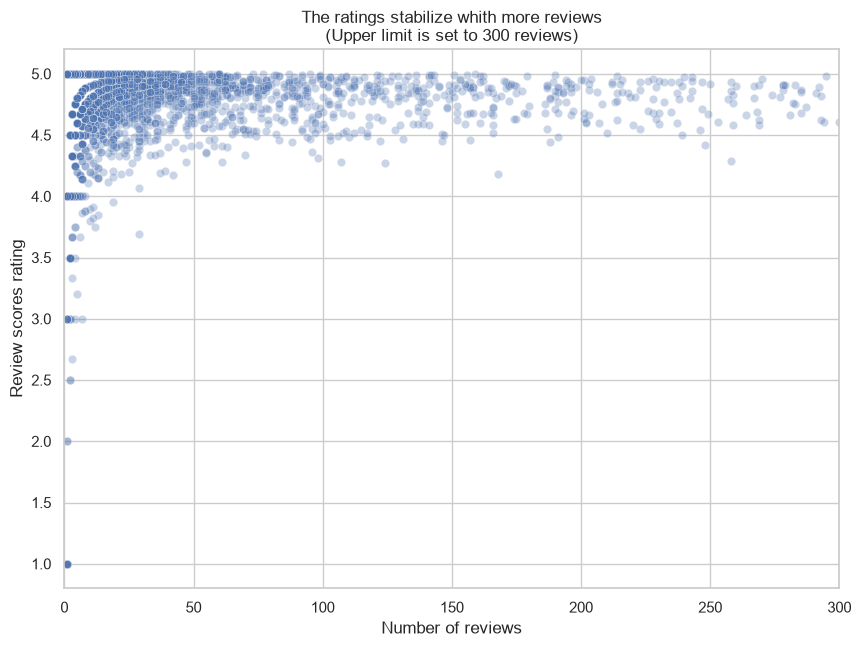

In [79]:
fig, ax = plt.subplots(figsize=(10, 7))

sns.scatterplot(data=only_has_reviews, x="number_of_reviews", y="review_scores_rating", alpha=0.3, ax=ax)

ax.set_xlim(0, 300)
ax.set_title("The ratings stabilize whith more reviews\n(Upper limit is set to 300 reviews)")
ax.set_xlabel("Number of reviews")
ax.set_ylabel("Review scores rating")

plt.show()

### 2.

- We can say that the superhosts on average have more reviews, but we do not know what the cause is, or if the casality is the other way around (more reviews render you a superhost)

In [96]:
listings["host_is_superhost"].value_counts()

host_is_superhost
False    3837
True      737
Name: count, dtype: int64

In [103]:
excluded = listings["number_of_reviews"] > 300

print(listings[excluded].shape[0])

91


In [111]:
excluded_super = ((listings["number_of_reviews"] > 300)
                  & (listings["host_is_superhost"]))

excluded_not_super = ((listings["number_of_reviews"] > 300)
                  & (~listings["host_is_superhost"]))

print(listings[excluded_super].shape[0])
print(listings[excluded_not_super].shape[0])

47
44


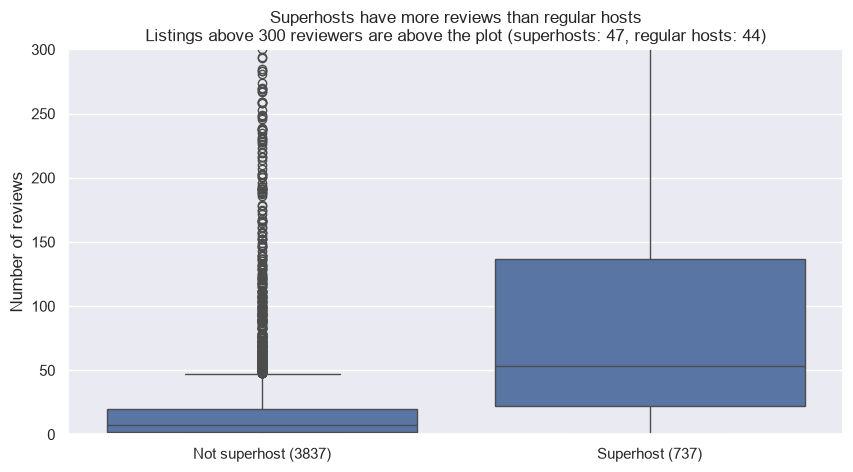

In [124]:
sns.set_theme(style="darkgrid")

is_superhost = listings[listings["host_is_superhost"].isin([True, False])]

fig, ax = plt.subplots(figsize=(10, 5))

sns.boxplot(data=is_superhost, x="host_is_superhost", y="number_of_reviews", ax=ax)

ax.set_ylim(0, 300)
ax.set_title(f"Superhosts have more reviews than regular hosts\nListings above 300 reviewers are above the plot (superhosts: {listings[excluded_super].shape[0]}, regular hosts: {listings[excluded_not_super].shape[0]})")
ax.set_ylabel("Number of reviews")
ax.set_xlabel("")
ax.set_xticks([0, 1])
ax.set_xticklabels([
    f"Not superhost ({(is_superhost["host_is_superhost"] == False).sum()})", 
    f"Superhost ({(is_superhost["host_is_superhost"] == True).sum()})"])

plt.show()

### 3.

a)
- The visuals do not represent reality well, the plot should start at 0 and not have those limits on the y-axis.
- The conclusion (title) seems to be drawn from the visuals which are (as stated above) not representative. A big deal is made of a miniscule difference in medians.
- As alluded to above.. Why make the whole plot on two medians? The plot makes those two numbers harder to understand rather than easier.
- Any number that tells us something about the dataset would be nice, how many, what is excluded etc.
- It acctually doesnt say what the y-axis represent, so we need to see the code to know that it is medians that are compared.

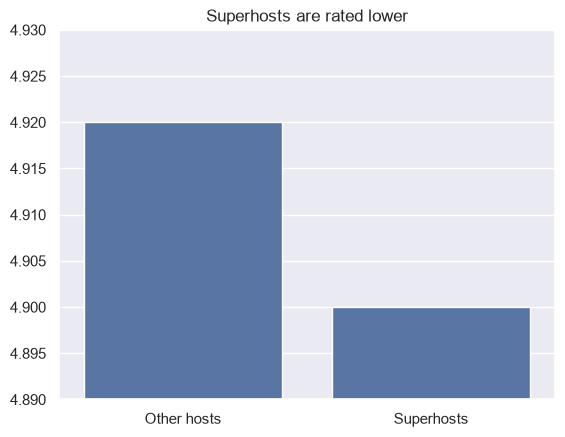

In [121]:
medians = listings.groupby('host_is_superhost')['review_scores_rating'].median()

fig, ax = plt.subplots()
sns.barplot(x=['Other hosts', 'Superhosts'], y=medians.values, ax=ax)
ax.set_ylim(4.89, 4.93)
ax.set_title('Superhosts are rated lower')
plt.show()

b)

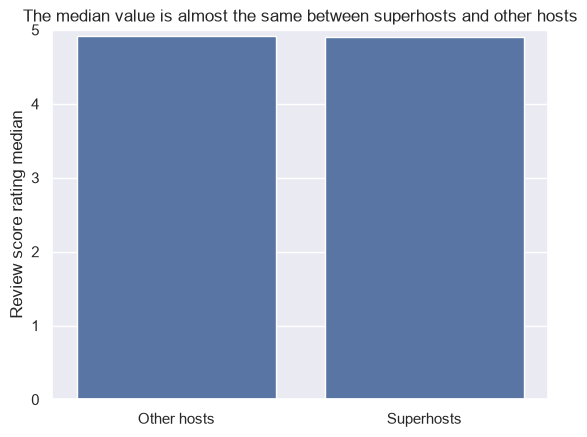

In [137]:
medians = listings.groupby('host_is_superhost')['review_scores_rating'].median()

fig, ax = plt.subplots()
sns.barplot(x=['Other hosts', 'Superhosts'], y=medians.values, ax=ax)
ax.set_title("The median value is almost the same between superhosts and other hosts")
ax.set_ylim(0, 5)
ax.set_ylabel("Review score rating median")
ax.set_xlabel("")
plt.show()

fig.savefig("superhost_rating.png", dpi=150, bbox_inches="tight")

c)
- The median and the mean are fairly close which would mean that a lot of values are probably at approximatly the same place for both groups.
- Above also means that the median is probably not the right measure if you wanted to find any differences between the groups. But the mean isnt that informative either for that in this case.
- If there is any interesting difference at all it is probably in the lower part of the distribution. So maybe two scatterplots(one for each group) against number of reviews could be a good start to find out if there even is a meaningful difference between the groups. If we wanted to keep the question as is and not introduce other variables a boxplot is better for showing the spread of values.
- So the barchart is probably not the right tool, unless you wanted the number of superhosts compared to regular hosts or something like that, which would just be a percentage presented visually. Barcharts are more useful for showing differences between many categories: Here we have two categories and practicly no differences.

In [130]:
superhost_vs_not = (listings.groupby("host_is_superhost")["review_scores_rating"]
                    .agg(["median", "mean", "count"])).round(2)

print(superhost_vs_not)

                   median  mean  count
host_is_superhost                     
False                4.92  4.81   3215
True                 4.90  4.87    715


In [136]:
(listings.groupby("host_is_superhost")["review_scores_rating"]).describe().round(2)

,count,mean,std,min,25%,50%,75%,max
host_is_superhost,,,,,,,,
False,3215.0,4.81,0.34,1.0,4.72,4.92,5.00,5.0
True,715.0,4.87,0.15,3.5,4.83,4.90,4.96,5.0


### 4.

- Q: Are there any regions where people are more inclined to leave a review?
- I choose the barchart so that the 14 regions are easily visable. I choose median number of reviews so that any extremes would have less effect since this is not about the listings per se, but how the customers interact with listings in different regions in general.
- There is no cuts of the data in this chart but it would leave out any listings without a "neighbourhood_cleansed" value. But there are none of those.
- A comparison with the mean value could be of interest, but depending on who is supposed to be reading it a boxplot could be to much information at one place.
- The chart does not tell us any reason why it is like it is, so any conlusion other than that the medians are as they are would be speculation. We can for example not say that many listings = higher median number of reviews. Other things we cannot say is why people seem to behave differently based on the regions they rent in. That though would make an interesting investigation in it self, but would require other datapoints, and possibly datapoints that are of a less quantitative in nature.

In [172]:
listings["neighbourhood_cleansed"].value_counts(dropna=False)

neighbourhood_cleansed
Södermalms                1145
Norrmalms                  469
Hägersten-Liljeholmens     464
Enskede-Årsta-Vantörs      445
Kungsholmens               420
Östermalms                 297
Bromma                     281
Skarpnäcks                 221
Älvsjö                     214
Farsta                     177
Hässelby-Vällingby         148
Rinkeby-Tensta             108
Skärholmens                 96
Spånga-Tensta               89
Name: count, dtype: int64

In [169]:
region_reviews = (
    listings.groupby("neighbourhood_cleansed")["number_of_reviews"]
    .agg(["median", "count"])
    .sort_values("median", ascending=False)
    .reset_index()
)

region_reviews["label"] = (
    region_reviews["neighbourhood_cleansed"]
    + " ("
    + region_reviews["count"].astype(str)
    + ")"
)
print(region_reviews)

    neighbourhood_cleansed  median  count                         label
0               Södermalms    17.0   1145             Södermalms (1145)
1             Kungsholmens    12.0    420            Kungsholmens (420)
2                Norrmalms    10.0    469               Norrmalms (469)
3               Östermalms     9.0    297              Östermalms (297)
4                   Älvsjö     8.5    214                  Älvsjö (214)
5   Hägersten-Liljeholmens     8.0    464  Hägersten-Liljeholmens (464)
6               Skarpnäcks     8.0    221              Skarpnäcks (221)
7            Spånga-Tensta     7.0     89            Spånga-Tensta (89)
8    Enskede-Årsta-Vantörs     7.0    445   Enskede-Årsta-Vantörs (445)
9                   Bromma     5.0    281                  Bromma (281)
10          Rinkeby-Tensta     5.0    108          Rinkeby-Tensta (108)
11                  Farsta     4.0    177                  Farsta (177)
12      Hässelby-Vällingby     4.0    148      Hässelby-Vällingb

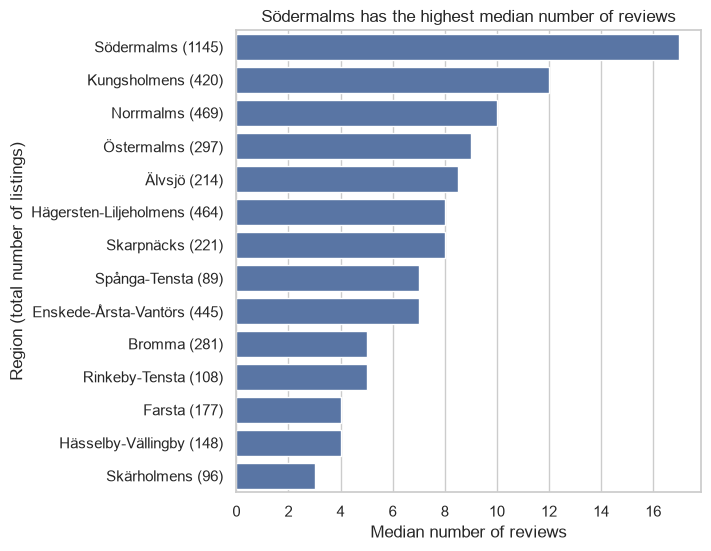

In [ ]:

sns.set_theme(style="whitegrid")

fig, ax = plt.subplots(figsize=(6, 6))

sns.barplot(data=region_reviews, x="median", y="label", ax=ax)

ax.set_title("Södermalm(s) has the highest median number of reviews")
ax.set_xlabel("Median number of reviews")
ax.set_ylabel("Region (total number of listings)")

plt.show()